In [14]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB # naive bayes multinomial para clasificación
from sklearn.metrics import accuracy_score # métrica de evaluación

# Análisis Exploratorio

In [ ]:
df_casas_entrenamiento = pd.read_csv('datasets/casas_entrenamiento.csv')
df_casas_entrenamiento.head(5)

In [ ]:
df_casas_predecir = pd.read_csv('datasets/casas_predecir.csv')
df_casas_predecir.head(5)

Usamos `id` como índice (sugerencia del enunciado). `set_index` devuelve un DataFrame nuevo, por eso hay que reasignarlo; si no, el cambio se pierde.

El id no es una característica de la casa. Es un código al azar que no dice nada sobre si paga comisión. Si queda como columna, es fácil que termine entrando al modelo sin querer, por ejemplo al hacer df.drop(columns='paga_comision') para armar X. Tiene 61.577 valores distintos, uno por fila, así que solo aporta ruido. Y con one-hot encoding generaría 61.577 columnas nuevas. Como índice queda fuera de X sin que tengas que acordarte de sacarlo.
Cada predicción sigue atada a su casa. El índice acompaña a cada fila cuando filtrás, separás en train/test o eliminás nulos. Al final, armar el entregable es directo:
pred = modelo.predict(X_predecir)
ids_paga = X_predecir.index[pred == 'paga']
pd.DataFrame(index=ids_paga).to_csv('casas_entrega.csv')
   Sin el índice, después de filtrar filas tendrías que volver a emparejar a mano cada predicción con su id, y ahí aparecen los errores.
Permite controlar los errores que el enunciado advierte. El PDF pide verificar que los ids del entregable pertenezcan a casas_predecir.csv y no a los de entrenamiento:
assert ids_paga.isin(df_casas_predecir.index).all()
assert not ids_paga.isin(df_casas_entrenamiento.index).any()

## Trampas de estructura (1/3): columnas de cada archivo

**Por qué:** el modelo se entrena con las columnas de `casas_entrenamiento` y después se aplica a `casas_predecir`. Si un archivo tiene una columna que el otro no, o la misma columna con otro tipo de dato, el modelo falla al predecir o usa información que no va a estar disponible.

**Qué hace:** arma una tabla con todas las columnas de los dos archivos, una al lado de la otra, con el tipo de dato en cada uno y si coinciden. Debajo lista las columnas que están en un solo archivo.

In [ ]:
# Comparación de columnas entre los dos archivos

# Si ya se corrió set_index("id"), id pasó al índice: trabajamos sobre una copia con id como columna.
# Así la celda da lo mismo sin importar el orden en que se ejecutó el notebook (no modifica los originales).
tr = df_casas_entrenamiento if 'id' in df_casas_entrenamiento.columns else df_casas_entrenamiento.reset_index()
pr = df_casas_predecir if 'id' in df_casas_predecir.columns else df_casas_predecir.reset_index()

# Tabla con todas las columnas de ambos datasets, una al lado de la otra.
# Si una columna falta en un archivo, su tipo aparece como NaN en esa fila.
comparacion_columnas = pd.DataFrame({
    'casas_entrenamiento': tr.dtypes,
    'casas_predecir': pr.dtypes,
})
comparacion_columnas['tipos_iguales'] = comparacion_columnas['casas_entrenamiento'] == comparacion_columnas['casas_predecir']
print("Cantidad de columnas -> entrenamiento:", tr.shape[1], "| predecir:", pr.shape[1])
display(comparacion_columnas)

# Columnas presentes en un archivo y no en el otro
cols_tr, cols_pr = set(tr.columns), set(pr.columns)
print("Solo en entrenamiento:", sorted(cols_tr - cols_pr))
print("Solo en predecir:     ", sorted(cols_pr - cols_tr))

## Trampas de estructura (2/3): ids duplicados y compartidos

**Por qué:** `id` va a ser el índice y es lo único que se entrega en `casas_entrega.csv`. Si un id se repite dentro de un archivo, una misma predicción quedaría asociada a dos casas. Si un id aparece en los dos archivos, se podría terminar entregando un id de entrenamiento, que es justo el error que advierte el enunciado.

**Qué hace:** cuenta filas, ids únicos e ids repetidos en cada archivo, y calcula cuántos ids comparten casas_entrenamiento y casas_predecir. Al final, tres `assert` frenan el notebook si alguna de estas condiciones no se cumple, para no seguir trabajando sobre una base rota.

In [22]:
# Ids duplicados dentro de cada archivo y compartidos entre ambos
# Si ya se corrió set_index("id"), trabajamos sobre una copia con id como columna (no modifica los originales)
tr = df_casas_entrenamiento if 'id' in df_casas_entrenamiento.columns else df_casas_entrenamiento.reset_index()
pr = df_casas_predecir if 'id' in df_casas_predecir.columns else df_casas_predecir.reset_index()

datasets = {'casas_entrenamiento': tr, 'casas_predecir': pr}
for nombre, df in datasets.items():
    print(f"[{nombre}] filas: {len(df)} | ids únicos: {df['id'].nunique()} | ids duplicados: {df['id'].duplicated().sum()}")
ids_compartidos = set(tr['id']) & set(pr['id'])
print("Ids compartidos entre entrenamiento y predecir:", len(ids_compartidos))

# Verificaciones que el resto del notebook da por hechas
assert tr['id'].is_unique, "Hay ids repetidos en entrenamiento"
assert pr['id'].is_unique, "Hay ids repetidos en predecir"
assert len(ids_compartidos) == 0, "Hay ids compartidos entre entrenamiento y predecir"

[casas_entrenamiento] filas: 61577 | ids únicos: 61577 | ids duplicados: 0
[casas_predecir] filas: 41054 | ids únicos: 41054 | ids duplicados: 0
Ids compartidos entre entrenamiento y predecir: 0


## Trampas de estructura (3/3): filas duplicadas

**Por qué:** una misma propiedad puede estar publicada varias veces con distinto id (avisos re-publicados). Eso trae tres problemas:
- Si una copia queda en train y otra en test, el modelo "reconoce" la casa en vez de predecirla y la ganancia estimada sale optimista.
- Si las copias tienen etiquetas distintas, hay ruido en la variable objetivo.
- Si una casa de predecir es idéntica a una de entrenamiento, su etiqueta ya se conoce.

**Qué hace:** en cada archivo cuenta los duplicados exactos (todas las columnas) y los duplicados ignorando `id` y `paga_comision` (en predecir esa columna es relleno). En entrenamiento cuenta cuántos grupos de casas idénticas tienen etiquetas contradictorias. Por último, cruza los dos archivos para contar cuántas filas de predecir son idénticas a alguna de entrenamiento.

In [23]:
# Filas duplicadas
# Si ya se corrió set_index("id"), trabajamos sobre una copia con id como columna (no modifica los originales)
tr = df_casas_entrenamiento if 'id' in df_casas_entrenamiento.columns else df_casas_entrenamiento.reset_index()
pr = df_casas_predecir if 'id' in df_casas_predecir.columns else df_casas_predecir.reset_index()

# - exactas (todas las columnas, incluido id)
# - "misma propiedad con otro id": se ignoran id y paga_comision (en predecir es relleno)
features = [c for c in tr.columns if c not in ('id', 'paga_comision')]
for nombre, df in {'casas_entrenamiento': tr, 'casas_predecir': pr}.items():
    print(f"[{nombre}] duplicados exactos: {df.duplicated().sum()} | "
          f"duplicados ignorando id: {df.duplicated(subset=features).sum()}")

# En entrenamiento: ¿hay duplicados con etiquetas distintas? (misma casa, una 'paga' y otra 'no paga')
etiquetas_por_casa = tr.groupby(features, dropna=False)['paga_comision'].nunique()
print("\nGrupos de duplicados en entrenamiento con etiqueta contradictoria:", (etiquetas_por_casa > 1).sum())

# Entre archivos: filas de predecir idénticas a alguna de entrenamiento (sin contar id ni target)
cruce = pr[features].merge(tr[features].drop_duplicates(), how='inner', on=features)
print("Filas de predecir idénticas a una de entrenamiento:", len(cruce))

[casas_entrenamiento] duplicados exactos: 0 | duplicados ignorando id: 867
[casas_predecir] duplicados exactos: 0 | duplicados ignorando id: 425

Grupos de duplicados en entrenamiento con etiqueta contradictoria: 16
Filas de predecir idénticas a una de entrenamiento: 907


[casas_entrenamiento] duplicados exactos: 0 | duplicados ignorando id: 867    -> Hay que eliminar los duplicados del set de entrenamiento porque producen overfitting

[casas_predecir] duplicados exactos: 0 | duplicados ignorando id: 425         -> No hace falta eliminarlos ya que pueden ser duplicados reales

Grupos de duplicados en entrenamiento con etiqueta contradictoria: 16         -> Los 33 grupos hay que eliminarlos ya que precentan contradicción para el modelo

Filas de predecir idénticas a una de entrenamiento: 907                       -> Eliminamos las filas del set de entrenamiento ya que el dataset de producción debe predecirse completo. Asi tambien evitamos dataleaks

## Limpieza de duplicados (1/3): casas con etiqueta contradictoria (son los 33 grupos)

**Por qué:** hay propiedades idénticas en todas sus columnas (salvo `id`) que en una fila figuran como `paga` y en otra como `no paga`. Con los mismos datos de entrada, el modelo recibe dos respuestas opuestas: es ruido que no puede aprender. Como no hay forma de saber cuál etiqueta es la correcta, se eliminan **todas** las filas de esos grupos, sin elegir una. Este paso va antes de quitar los duplicados: si se deduplicara primero, cada grupo quedaría en una sola fila con una etiqueta elegida al azar y la contradicción ya no se vería.

**Qué hace:** calcula una "huella" de cada fila a partir de todas las columnas menos `id` y `paga_comision` (filas idénticas tienen la misma huella). Cuenta cuántas etiquetas distintas tiene cada huella y elimina del entrenamiento las filas cuya huella tiene más de una.

In [25]:
# Columnas que describen la casa: todas menos id y el target
# (funciona tanto si id es columna como si ya es el índice)
features = [c for c in df_casas_entrenamiento.columns if c not in ('id', 'paga_comision')]

# Huella de cada fila: filas idénticas en 'features' tienen el mismo número (los NaN también se comparan bien)
huella_tr = pd.util.hash_pandas_object(df_casas_entrenamiento[features], index=False)

# Para cada fila, cuántas etiquetas distintas tiene su grupo de casas idénticas
etiquetas_en_grupo = df_casas_entrenamiento.groupby(huella_tr)['paga_comision'].transform('nunique')
contradictorias = etiquetas_en_grupo > 1

filas_antes = len(df_casas_entrenamiento)
print("Grupos con etiqueta contradictoria:", huella_tr[contradictorias].nunique())
print("Filas a eliminar (todas las de esos grupos):", contradictorias.sum())

df_casas_entrenamiento = df_casas_entrenamiento[~contradictorias]
print(f"Entrenamiento: {filas_antes} -> {len(df_casas_entrenamiento)} filas")

# Verificación: ya no queda ninguna casa con dos etiquetas distintas
huella_tr = pd.util.hash_pandas_object(df_casas_entrenamiento[features], index=False)
assert (df_casas_entrenamiento.groupby(huella_tr)['paga_comision'].nunique() == 1).all()

Grupos con etiqueta contradictoria: 16
Filas a eliminar (todas las de esos grupos): 33
Entrenamiento: 61577 -> 61544 filas


## Limpieza de duplicados (2/3): duplicados dentro del entrenamiento

**Por qué:** una misma casa publicada varias veces con distinto `id` pesa doble en el entrenamiento, y al separar train/test una copia puede quedar de cada lado. En ese caso el modelo "reconoce" la casa en vez de predecirla, sobreajusta y la ganancia estimada en test sale más alta de lo que va a ser con casas nuevas. En `casas_predecir` no se eliminan: hay que entregar una predicción para cada `id`.

**Qué hace:** elimina las filas del entrenamiento que son idénticas a otra en todas las columnas menos `id` (la etiqueta ya coincide, porque las contradictorias se quitaron en el paso anterior). Conserva la primera aparición de cada casa.

In [26]:
# Duplicados de la misma casa con distinto id (se ignora id; la etiqueta ya es consistente)
features = [c for c in df_casas_entrenamiento.columns if c not in ('id', 'paga_comision')]

filas_antes = len(df_casas_entrenamiento)
print("Duplicados a eliminar:", df_casas_entrenamiento.duplicated(subset=features).sum())

# keep='first': de cada grupo de casas idénticas queda la primera fila
df_casas_entrenamiento = df_casas_entrenamiento.drop_duplicates(subset=features, keep='first')
print(f"Entrenamiento: {filas_antes} -> {len(df_casas_entrenamiento)} filas")

# Verificación: no quedan casas repetidas en el entrenamiento
assert not df_casas_entrenamiento.duplicated(subset=features).any()

Duplicados a eliminar: 850
Entrenamiento: 61544 -> 60694 filas


## Limpieza de duplicados (3/3): casas de entrenamiento que también están en predecir

**Por qué:** hay casas de `casas_predecir` idénticas a casas del entrenamiento. `casas_predecir` es el dataset de producción y se predice completo, así que de ahí no se puede sacar nada; las coincidencias se quitan del entrenamiento. Así los dos conjuntos quedan disjuntos: el modelo se entrena y se valida solo con casas que no va a tener que predecir, y su rendimiento estimado refleja lo que va a pasar con casas nuevas, no con casas que ya vio.

**Qué hace:** calcula la huella (todas las columnas menos `id` y `paga_comision`) de cada fila de los dos archivos y elimina del entrenamiento las filas cuya huella aparece en `casas_predecir`. `casas_predecir` no se modifica.

In [27]:
# Casas del entrenamiento idénticas a alguna de predecir (sin contar id ni target)
features = [c for c in df_casas_entrenamiento.columns if c not in ('id', 'paga_comision')]

huella_tr = pd.util.hash_pandas_object(df_casas_entrenamiento[features], index=False)
huella_pr = pd.util.hash_pandas_object(df_casas_predecir[features], index=False)
en_predecir = huella_tr.isin(huella_pr)

filas_antes, filas_predecir = len(df_casas_entrenamiento), len(df_casas_predecir)
print("Filas de entrenamiento que también están en predecir:", en_predecir.sum())
print("Filas de predecir afectadas (se mantienen):", huella_pr.isin(huella_tr).sum())

df_casas_entrenamiento = df_casas_entrenamiento[~en_predecir]
print(f"Entrenamiento: {filas_antes} -> {len(df_casas_entrenamiento)} filas")

# Verificaciones: los conjuntos quedaron disjuntos y predecir no perdió filas
huella_tr = pd.util.hash_pandas_object(df_casas_entrenamiento[features], index=False)
assert not huella_tr.isin(huella_pr).any()
assert len(df_casas_predecir) == filas_predecir

Filas de entrenamiento que también están en predecir: 708
Filas de predecir afectadas (se mantienen): 902
Entrenamiento: 60694 -> 59986 filas


In [29]:
import re
import unicodedata
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, TargetEncoder

# ============================================================================
# 0) FUERA DEL PIPELINE: id como índice y separación de X / y.
#    El target nunca va dentro de las predictoras (error común), y el Pipeline
#    estándar no puede eliminar filas, por eso la limpieza de duplicados quedó antes.
# ============================================================================
def id_como_indice(df):
    # id no describe la casa, pero lo necesitamos para el entregable
    return df.set_index('id') if 'id' in df.columns else df

entrenamiento = id_como_indice(df_casas_entrenamiento)
y = (entrenamiento['paga_comision'] == 'paga').astype(int)                    # 1 = paga, 0 = no paga
X = entrenamiento.drop(columns=['paga_comision'])
X_predecir = id_como_indice(df_casas_predecir).drop(columns=['paga_comision'])  # en predecir es relleno


# ============================================================================
# 1) PASOS "STATELESS" -> FunctionTransformer
#    Reglas fijas que no aprenden nada de los datos: dan lo mismo en train,
#    test y predecir, así que no pueden generar fuga.
# ============================================================================

# ad_type: un solo valor | l6: 100% vacía | created_on: idéntica a start_date
# lat/lon, l4, l5, price_period: decisión del análisis
# start_date/end_date: casi no cambian la tasa de pago (quedan fuera del modelo base)
COLUMNAS_A_ELIMINAR = ['ad_type', 'l6', 'created_on', 'lat', 'lon', 'l4', 'l5',
                       'price_period', 'start_date', 'end_date']

def eliminar_columnas(X):
    return X.drop(columns=COLUMNAS_A_ELIMINAR)


def invalidos_a_nan(X):
    # Valores imposibles -> NaN (no se borran filas: en predecir hay que predecir todas)
    X = X.copy()
    # bedrooms: 0 es un faltante disfrazado (casas de US$ 550.000 con 0 dormitorios); negativos y > 15 son imposibles
    X.loc[(X['bedrooms'] <= 0) | (X['bedrooms'] > 15), 'bedrooms'] = np.nan
    # bathrooms: más de 8 baños se considera error de carga
    X.loc[X['bathrooms'] > 8, 'bathrooms'] = np.nan
    # superficies: 0, negativas o menores a 20 m² no son posibles para una casa
    X.loc[X['surface_total'] < 20, 'surface_total'] = np.nan
    X.loc[X['surface_covered'] < 20, 'surface_covered'] = np.nan
    # cubierta > total es inconsistente: se descarta la total (la cubierta tiene menos errores)
    X.loc[X['surface_covered'] > X['surface_total'], 'surface_total'] = np.nan
    return X


# Marcas de moneda en dólares que aceptamos en el título. '$' solo NO: es ambiguo (pesos o dólares)
PATRON_PRECIO = re.compile(r'(?:u\$s|u\$d|usd|us\$|u\$)\s*(\d[\d\.,]*)')

def normalizar_texto(texto):
    # Minúsculas y sin tildes, para que 'Dúplex' y 'DUPLEX' se detecten igual
    texto = unicodedata.normalize('NFKD', str(texto).lower())
    return ''.join(c for c in texto if not unicodedata.combining(c))

def extraer_precio_usd(texto):
    # Busca 'U$S 190.000', 'USD 580.000', 'U$425.000', etc. Devuelve el número, o NaN si no hay precio
    m = PATRON_PRECIO.search(texto)
    if not m:
        return np.nan
    numero = re.sub(r'[\.,]\d{1,2}$', '', m.group(1).rstrip('.,'))  # saca decimales tipo ',00'
    numero = re.sub(r'[\.,]', '', numero)                            # saca separadores de miles
    if not numero:
        return np.nan
    valor = float(numero)
    # Fuera de un rango razonable es un número cortado ('U$D 550.') o mal escrito: no se usa
    return valor if 10_000 <= valor <= 50_000_000 else np.nan


def crear_features(X):
    X = X.copy()

    # l3 (ciudad): el nulo pasa a ser una categoría propia, porque tiene su propia tasa de pago
    X['l3'] = X['l3'].fillna('Sin dato')

    # Indicadores de nulo: se crean ANTES de imputar, porque que falte el dato informa sobre el target
    for col in ['rooms', 'bedrooms', 'bathrooms', 'surface_total', 'surface_covered']:
        X[f'{col}_faltante'] = X[col].isna().astype(int)

    # m2_descubiertos: patio/jardín (total - cubierta). Con m² reales, antes del log y de imputar
    X['m2_descubiertos'] = X['surface_total'] - X['surface_covered']

    # Imputación por regla de dominio (en Argentina, ambientes = dormitorios + 1)
    rooms_orig, bedrooms_orig = X['rooms'].copy(), X['bedrooms'].copy()
    X['rooms'] = rooms_orig.fillna(bedrooms_orig + 1)
    X['bedrooms'] = bedrooms_orig.fillna((rooms_orig - 1).where(rooms_orig >= 2))
    # surface_total sin dato pero con cubierta: la cubierta es un mínimo seguro de la total
    X['surface_total'] = X['surface_total'].fillna(X['surface_covered'])

    # Superficies en log: tienen cola larga (hasta 200.000 m²) y el log la comprime sin borrar datos
    X['surface_total'] = np.log1p(X['surface_total'])
    X['surface_covered'] = np.log1p(X['surface_covered'])

    # --- Variables nuevas a partir de title ---
    titulo = X['title'].fillna('').map(normalizar_texto)
    # Alquileres: el precio que traen no es de venta, así que no se usa como precio
    X['es_alquiler'] = titulo.str.contains(r'\b(?:alquiler|alquilo|temporada)\b', regex=True).astype(int)
    # precio_usd: la variable más fuerte (con precio > 500k paga el 99,9%). NaN si el título no lo trae
    X['precio_usd'] = titulo.map(extraer_precio_usd).where(X['es_alquiler'] == 0)
    X['tiene_precio'] = X['precio_usd'].notna().astype(int)
    # Tipo de propiedad: el dataset no lo tiene como columna y la tasa de pago varía mucho según el tipo
    X['es_duplex'] = titulo.str.contains(r'\bduplex\b', regex=True).astype(int)
    X['es_ph'] = titulo.str.contains(r'\bph\b', regex=True).astype(int)
    X['es_depto'] = titulo.str.contains(r'\b(?:depto|dpto|departamento)s?\b', regex=True).astype(int)
    X['es_chalet'] = titulo.str.contains(r'\bchalet\b', regex=True).astype(int)
    X['es_lote'] = titulo.str.contains(r'\blote\b', regex=True).astype(int)
    # Palabras de lujo o de estado: suben (piscina, country, barrio cerrado) o bajan (a reciclar) la tasa
    X['tiene_piscina'] = titulo.str.contains(r'\b(?:piscina|pileta)\b', regex=True).astype(int)
    X['es_country'] = titulo.str.contains(r'\bcountry\b', regex=True).astype(int)
    X['barrio_cerrado'] = titulo.str.contains(r'\bbarrio cerrado\b', regex=True).astype(int)
    X['a_reciclar'] = titulo.str.contains(r'reciclar', regex=True).astype(int)

    # El texto original ya no aporta: todo lo útil quedó en las columnas nuevas
    return X.drop(columns=['title'])


# ============================================================================
# 2) PASO CON MEMORIA -> CustomTransformer
#    El tope de surface_covered se APRENDE en fit (solo con train) y se APLICA
#    en transform (train, test y predecir). Un FunctionTransformer no sirve acá
#    porque no tiene memoria.
# ============================================================================
class RecortarMaximo(BaseEstimator, TransformerMixin):
    # Recorta valores absurdos (ej: 235.000 m² cubiertos) al percentil indicado, calculado en fit
    def __init__(self, columnas=None, percentil=0.999):
        self.columnas = columnas
        self.percentil = percentil

    def fit(self, X, y=None):
        self.topes_ = {c: X[c].quantile(self.percentil) for c in self.columnas}
        self.feature_names_in_ = np.asarray(X.columns)
        return self

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

    def transform(self, X):
        Xc = X.copy()  # copia: no modificamos el DataFrame que nos pasan
        for c, tope in self.topes_.items():
            Xc[c] = Xc[c].clip(upper=tope)
        return Xc


# ============================================================================
# 3) ColumnTransformer: transformaciones por columna que APRENDEN de los datos
#    (categorías, tasas por ciudad, medianas). set_output pandas conserva los nombres.
# ============================================================================
cols_numericas = ['rooms', 'bedrooms', 'bathrooms', 'surface_total', 'surface_covered',
                  'm2_descubiertos', 'precio_usd']
cols_binarias = ['rooms_faltante', 'bedrooms_faltante', 'bathrooms_faltante',
                 'surface_total_faltante', 'surface_covered_faltante',
                 'es_alquiler', 'tiene_precio', 'es_duplex', 'es_ph', 'es_depto', 'es_chalet',
                 'es_lote', 'tiene_piscina', 'es_country', 'barrio_cerrado', 'a_reciclar']

ct_encoding = ColumnTransformer([
    # l1 (país, 3 valores): one-hot; un país nuevo en predecir queda en ceros en vez de dar error
    ('l1', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['l1']),
    # l2 (región, 38 valores): one-hot agrupando las regiones con < 50 casas, cuya tasa es puro ruido
    ('l2', OneHotEncoder(min_frequency=50, handle_unknown='infrequent_if_exist', sparse_output=False), ['l2']),
    # l3 (ciudad, 560 valores): target encoding = tasa de pago de la ciudad, con validación cruzada interna
    ('l3', TargetEncoder(target_type='binary', random_state=42), ['l3']),
    # numéricas: lo que sigue faltando se imputa con la mediana de train (robusta a outliers)
    ('num', SimpleImputer(strategy='median'), cols_numericas),
    # binarias: ya están listas (0/1), pasan sin cambios
    ('bin', 'passthrough', cols_binarias),
], remainder='drop', verbose_feature_names_out=False)
ct_encoding.set_output(transform='pandas')


# ============================================================================
# 4) PIPELINE: encadena todo en orden. Al hacer fit, cada paso se ajusta solo con
#    los datos de entrenamiento; con transform/predict se aplica igual a test y predecir.
#    En la etapa de modelado se le agrega el estimador al final:
#    Pipeline([('preprocesamiento', preprocesamiento), ('modelo', ...)])
# ============================================================================
preprocesamiento = Pipeline([
    ('eliminar_columnas', FunctionTransformer(eliminar_columnas)),
    ('invalidos_a_nan', FunctionTransformer(invalidos_a_nan)),
    ('recortar_cubierta', RecortarMaximo(columnas=['surface_covered'], percentil=0.999)),
    ('crear_features', FunctionTransformer(crear_features)),
    ('encoding', ct_encoding),
])

# Verificaciones (no ajustan el pipeline: eso se hace en el modelado, solo con train)
assert 'paga_comision' not in X.columns and 'paga_comision' not in X_predecir.columns, "El target se coló en X"
assert list(X.columns) == list(X_predecir.columns), "Entrenamiento y predecir tienen columnas distintas"
assert len(X_predecir) == len(df_casas_predecir), "Se perdieron filas de predecir"
assert X.index.is_unique and X_predecir.index.is_unique, "Hay ids repetidos"
assert len(X) == len(y)

print("X:", X.shape, "| X_predecir:", X_predecir.shape, "| tasa de paga en y:", round(y.mean(), 4))
preprocesamiento  # muestra el diagrama del pipeline

X: (59986, 19) | X_predecir: (41054, 19) | tasa de paga en y: 0.111


Pipeline(steps=[('eliminar_columnas',
                 FunctionTransformer(func=<function eliminar_columnas at 0x7bbc1ba2fba0>)),
                ('invalidos_a_nan',
                 FunctionTransformer(func=<function invalidos_a_nan at 0x7bbc1ba2fce0>)),
                ('recortar_cubierta',
                 RecortarMaximo(columnas=['surface_covered'])),
                ('crear_features',
                 FunctionTransformer(func=<function crear_features at 0x7bbc1cb7f420>)),
                (...
                                                   'surface_covered',
                                                   'm2_descubiertos',
                                                   'precio_usd']),
                                                 ('bin', 'passthrough',
                                                  ['rooms_faltante',
                                                   'bedrooms_faltante',
                                                   'bathrooms_faltante',
                                                   'surface_total_faltante',
                                                   'surface_covered_faltante',
                                                   'es_alquiler',
                                                   'tiene_precio', 'es_duplex',
                                                   'es_ph', 'es_depto',
                                                   'es_chalet', 'es_lote',
                                                   'tiene_piscina',
                                                   'es_country',
                                                   'barrio_cerrado',
                                                   'a_reciclar'])],
                                   verbose_feature_names_out=False))])

In [ ]:
# Exportar cómo quedan los dos datasets después del pipeline (SOLO para inspección visual).
# Ojo: acá el pipeline se ajusta con TODO el entrenamiento. Para evaluar el modelo
# se ajusta solo con el train de cada split, así que estos archivos no se usan para medir nada.
entrenamiento_procesado = preprocesamiento.fit_transform(X, y)
predecir_procesado = preprocesamiento.transform(X_predecir)

# Agregamos el target al de entrenamiento para poder mirarlo junto a las features
entrenamiento_procesado['paga_comision'] = y

entrenamiento_procesado.to_csv('casas_entrenamiento_procesado.csv', index_label='id')
predecir_procesado.to_csv('casas_predecir_procesado.csv', index_label='id')
print("Entrenamiento procesado:", entrenamiento_procesado.shape, "| Predecir procesado:", predecir_procesado.shape)

In [5]:
df_casas_entrenamiento.dtypes

ad_type                str
start_date             str
end_date               str
created_on             str
lat                float64
lon                float64
l1                     str
l2                     str
l3                     str
l4                     str
l5                     str
l6                 float64
rooms              float64
bedrooms           float64
bathrooms          float64
surface_total      float64
surface_covered    float64
price_period           str
title                  str
paga_comision          str
dtype: object

In [6]:
df_casas_entrenamiento.describe(include='all')

,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,l4,l5,l6,rooms,bedrooms,bathrooms,surface_total,surface_covered,price_period,title,paga_comision
count,75966,75966,75966,75966,64854.000000,64631.000000,75966,75966,72837,29548,879,0.0,49910.000000,51361.000000,69173.000000,36459.000000,41669.000000,23829,75966,75966
unique,1,335,398,335,NaN,NaN,4,39,599,705,20,NaN,NaN,NaN,NaN,NaN,NaN,1,46839,2
top,Propiedad,2020-03-21,9999-12-31,2020-03-21,NaN,NaN,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,Nordelta,Barrio Los Alisos,NaN,NaN,NaN,NaN,NaN,NaN,Mensual,casa-venta,no paga
freq,75966,1472,25131,1472,NaN,NaN,74362,20309,7081,2372,180,NaN,NaN,NaN,NaN,NaN,NaN,23829,333,58057
mean,NaN,NaN,NaN,NaN,-34.443771,-59.353761,NaN,NaN,NaN,NaN,NaN,NaN,4.129954,2.981484,2.304396,513.777037,238.344333,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,4.321409,2.832762,NaN,NaN,NaN,NaN,NaN,NaN,1.677434,1.908883,1.211229,2644.001657,2143.020380,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,-54.828087,-180.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,1.000000,-2.000000,-5.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,-34.807490,-58.816697,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,2.000000,1.000000,170.000000,120.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,-34.642029,-58.561035,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,3.000000,2.000000,262.000000,175.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,-34.421031,-58.378182,NaN,NaN,NaN,NaN,NaN,NaN,5.000000,4.000000,3.000000,480.000000,250.000000,NaN,NaN,NaN


## Valores faltantes

l6                 100.00
l5                  98.84
price_period        68.63
l4                  61.10
surface_total       52.01
surface_covered     45.15
rooms               34.30
bedrooms            32.39
lon                 14.92
lat                 14.63
bathrooms            8.94
l3                   4.12
created_on           0.00
end_date             0.00
start_date           0.00
ad_type              0.00
l1                   0.00
l2                   0.00
title                0.00
paga_comision        0.00
dtype: float64


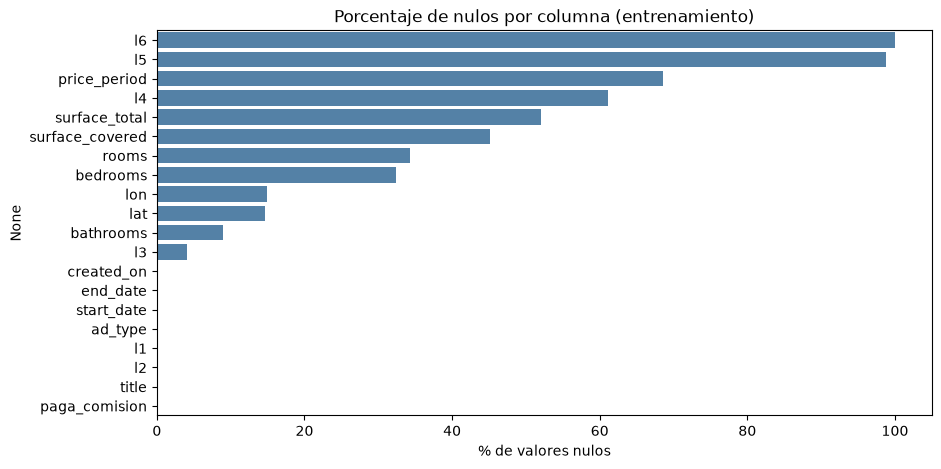

In [7]:
nulos = (df_casas_entrenamiento.isnull().mean() * 100).sort_values(ascending=False)
print(nulos.round(2))

plt.figure(figsize=(10,5))
sns.barplot(x=nulos.values, y=nulos.index, color='steelblue')
plt.xlabel('% de valores nulos')
plt.title('Porcentaje de nulos por columna (entrenamiento)')
plt.show()

## Limpieza inicial: columnas sin información

- `l6` está 100% vacía: no aporta nada al modelo, se elimina.
- `ad_type` tiene un único valor (`Propiedad`): es constante, tampoco aporta.

Detectamos ambas condiciones por código (en vez de hardcodear los nombres) y aplicamos **el mismo** drop a los dos datasets para que tengan las mismas columnas.

In [8]:
columnas_vacias = df_casas_entrenamiento.columns[df_casas_entrenamiento.isnull().all()].tolist()
columnas_constantes = [c for c in df_casas_entrenamiento.columns if df_casas_entrenamiento[c].nunique(dropna=True) == 1 and c not in columnas_vacias]
print("Columnas vacías:", columnas_vacias)
print("Columnas constantes:", columnas_constantes)

# price_period solo tiene 'Mensual' o NaN: no es constante si consideramos el NaN como categoría, la dejamos para analizarla
columnas_a_eliminar = [c for c in columnas_vacias + columnas_constantes if c != 'price_period']

df_casas_entrenamiento = df_casas_entrenamiento.drop(columns=columnas_a_eliminar)
df_casas_predecir = df_casas_predecir.drop(columns=columnas_a_eliminar)
print("Eliminadas:", columnas_a_eliminar)
print(df_casas_entrenamiento.shape, df_casas_predecir.shape)

Columnas vacías: ['l6']
Columnas constantes: ['ad_type', 'price_period']
Eliminadas: ['l6', 'ad_type']
(75966, 18) (50641, 18)


## Variable target: `paga_comision`

paga_comision
no paga    58057
paga       17909
Name: count, dtype: int64
paga_comision
no paga    76.42
paga       23.58
Name: proportion, dtype: float64


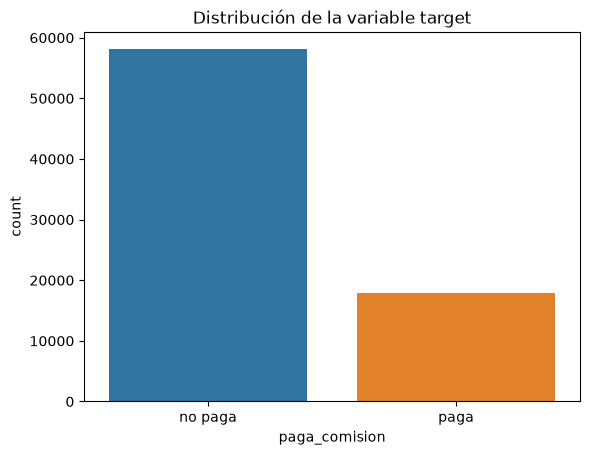

In [9]:
print( df_casas_entrenamiento.paga_comision.value_counts() )
print( (df_casas_entrenamiento.paga_comision.value_counts(normalize=True) * 100).round(2) )
sns.countplot(x='paga_comision', data=df_casas_entrenamiento, hue='paga_comision', legend=False)
plt.title('Distribución de la variable target')
plt.show()

El dataset está **desbalanceado** (~76% `no paga` vs ~24% `paga`). Un modelo que siempre diga `no paga` tendría un accuracy alto y ganancia nula, por eso hay que evaluar con la **función de ganancia** del enunciado y no solo con accuracy.

Para los gráficos trabajamos sobre una copia (`df_eda`) con el target en formato numérico (1 = paga), así el promedio de `target` por grupo es directamente la **tasa de pago de comisión**.

In [10]:
df_eda = df_casas_entrenamiento.copy()
df_eda['target'] = (df_eda.paga_comision == 'paga').astype(int)
tasa_global = df_eda.target.mean()
print(f"Tasa global de pago de comisión: {tasa_global:.2%}")

Tasa global de pago de comisión: 23.58%


## ¿Los nulos dicen algo sobre el target?
Si el porcentaje de nulos de una columna es distinto entre `paga` y `no paga`, el hecho de que falte el dato es información útil (se puede crear una feature indicadora de nulo en vez de solo imputar).

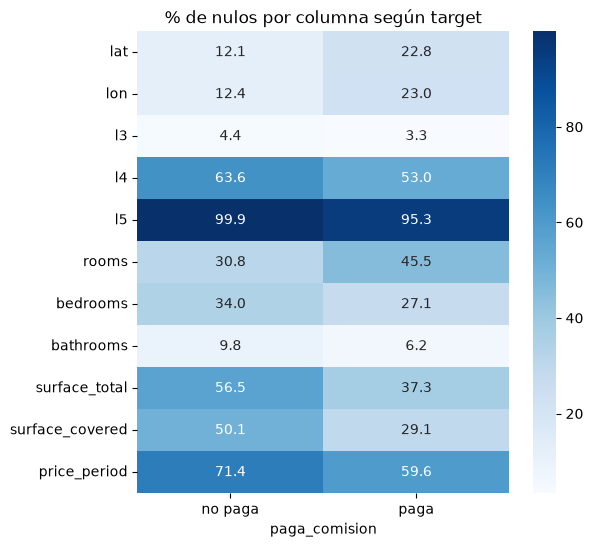

In [11]:
nulos_por_target = df_eda.drop(columns=['target']).isnull().groupby(df_eda.paga_comision).mean().T * 100
nulos_por_target = nulos_por_target[nulos_por_target.sum(axis=1) > 0]

plt.figure(figsize=(6,6))
sns.heatmap(nulos_por_target, annot=True, fmt='.1f', cmap='Blues')
plt.title('% de nulos por columna según target')
plt.show()

## Variables numéricas
Del `describe()` se ven valores imposibles: superficies negativas, `bedrooms` = 335, superficies de 200.000 m². Graficamos con escala logarítmica y recortando al percentil 99 para poder ver la forma real de las distribuciones.

In [12]:
numericas = ['rooms', 'bedrooms', 'bathrooms', 'surface_total', 'surface_covered']

print("Superficies <= 0:", (df_eda[['surface_total','surface_covered']] <= 0).sum().to_dict())
print("surface_covered > surface_total:", (df_eda.surface_covered > df_eda.surface_total).sum())
print("Percentil 99:")
print(df_eda[numericas].quantile(0.99))

Superficies <= 0: {'surface_total': 18, 'surface_covered': 1}
surface_covered > surface_total: 1035
Percentil 99:
rooms                10.00
bedrooms              6.00
bathrooms             6.00
surface_total      2844.20
surface_covered     700.64
Name: 0.99, dtype: float64


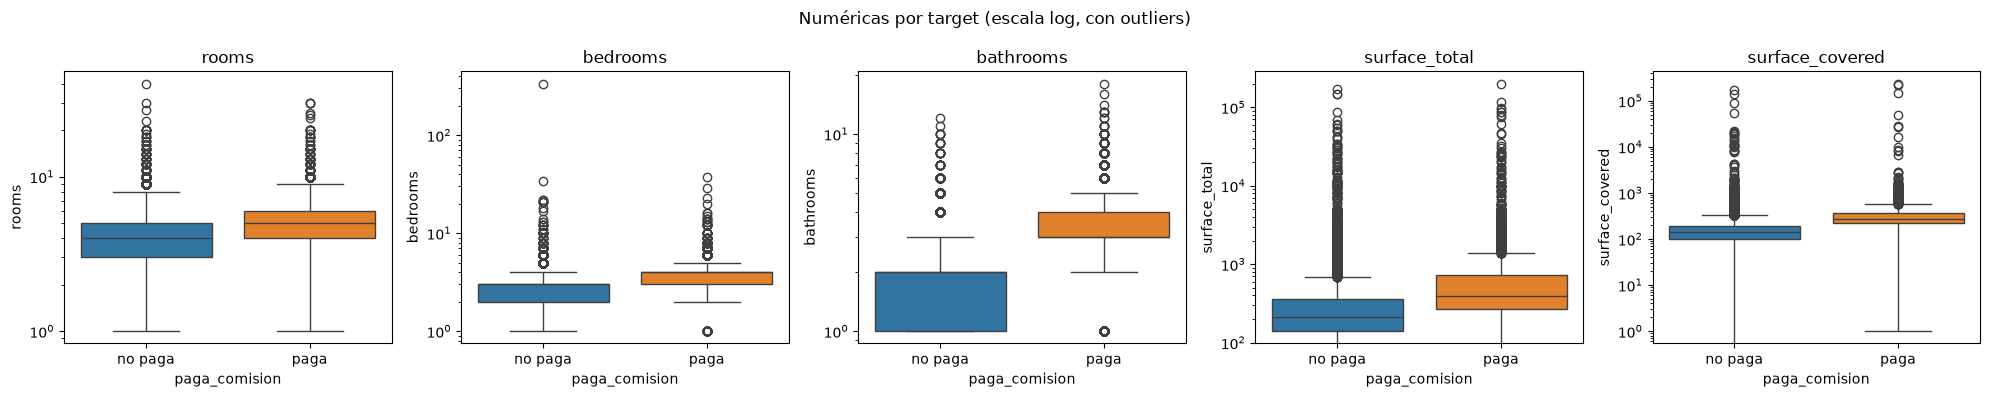

In [13]:
fig, axes = plt.subplots(1, len(numericas), figsize=(20,4))
for ax, col in zip(axes, numericas):
    sns.boxplot(x='paga_comision', y=col, data=df_eda, ax=ax, hue='paga_comision', legend=False)
    ax.set_yscale('log')
    ax.set_title(col)
plt.suptitle('Numéricas por target (escala log, con outliers)')
plt.tight_layout()
plt.show()

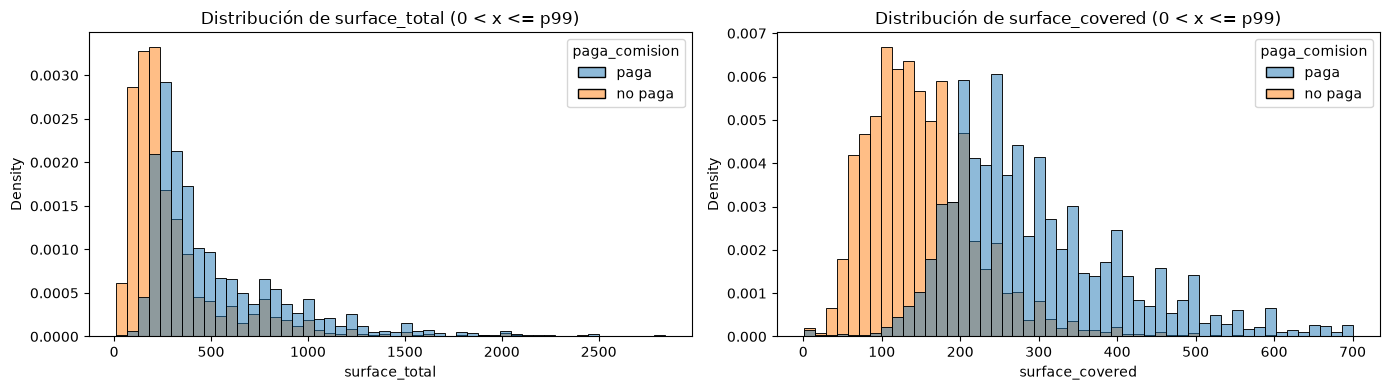

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14,4))
for ax, col in zip(axes, ['surface_total', 'surface_covered']):
    p99 = df_eda[col].quantile(0.99)
    datos = df_eda[(df_eda[col] > 0) & (df_eda[col] <= p99)]
    sns.histplot(data=datos, x=col, hue='paga_comision', bins=50, stat='density', common_norm=False, ax=ax)
    ax.set_title(f'Distribución de {col} (0 < x <= p99)')
plt.tight_layout()
plt.show()

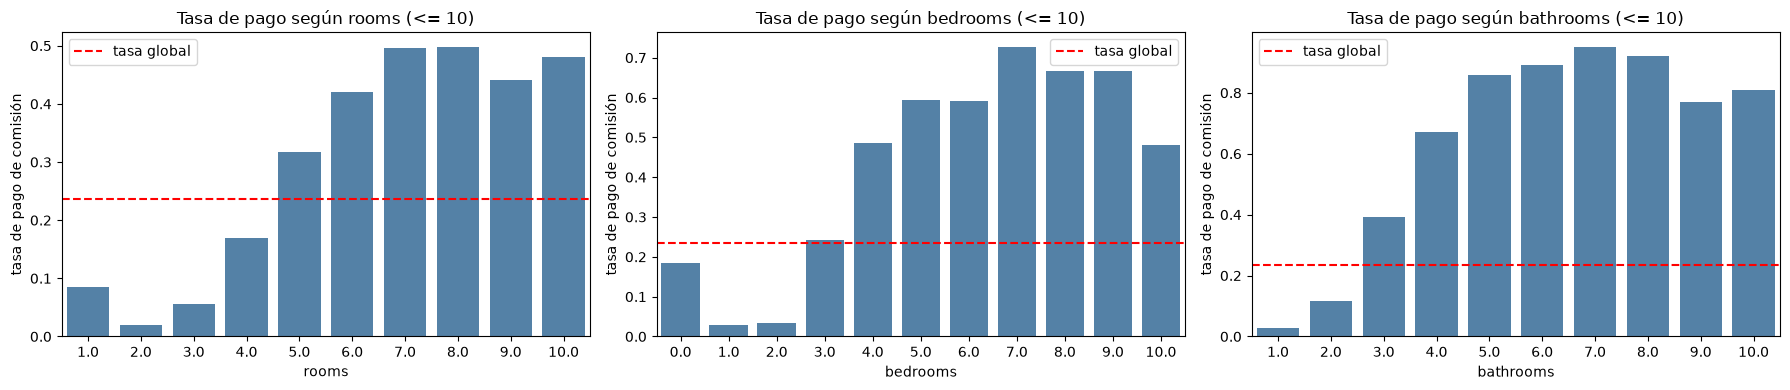

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18,4))
for ax, col in zip(axes, ['rooms', 'bedrooms', 'bathrooms']):
    datos = df_eda[df_eda[col] <= 10]
    sns.barplot(x=col, y='target', data=datos, ax=ax, color='steelblue', errorbar=None)
    ax.axhline(tasa_global, color='red', linestyle='--', label='tasa global')
    ax.set_ylabel('tasa de pago de comisión')
    ax.set_title(f'Tasa de pago según {col} (<= 10)')
    ax.legend()
plt.tight_layout()
plt.show()

## Correlación entre numéricas y target

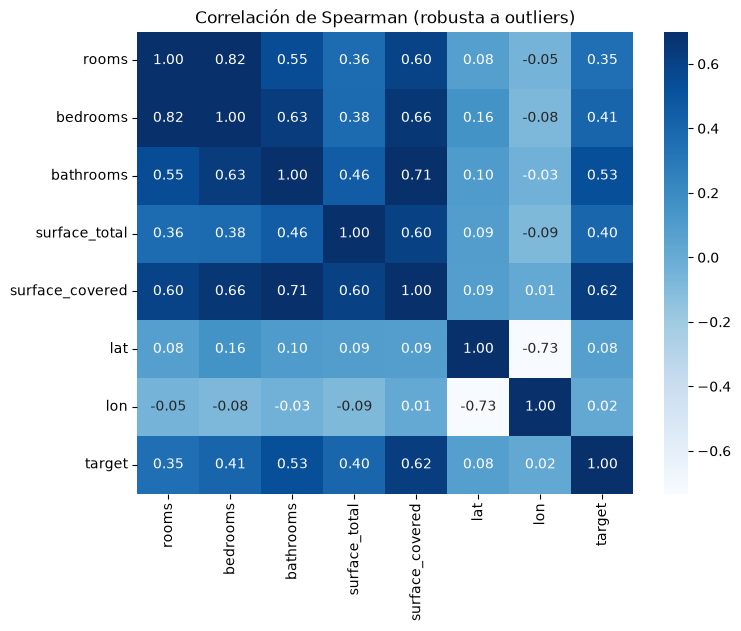

In [16]:
plt.figure(figsize=(8,6))
sns.heatmap(df_eda[numericas + ['lat', 'lon', 'target']].corr(method='spearman'), annot=True, fmt='.2f', cmap='Blues', vmax=.7)
plt.title('Correlación de Spearman (robusta a outliers)')
plt.show()

## Ubicación: país (`l1`) y provincia/región (`l2`)
`l1` y `l2` tienen pocas categorías, así que se pueden usar directamente (one-hot). `l3`, `l4` y `l5` tienen alta cardinalidad y requieren otro tratamiento (ver enunciado).

l1      4
l2     39
l3    599
l4    705
l5     20
dtype: int64


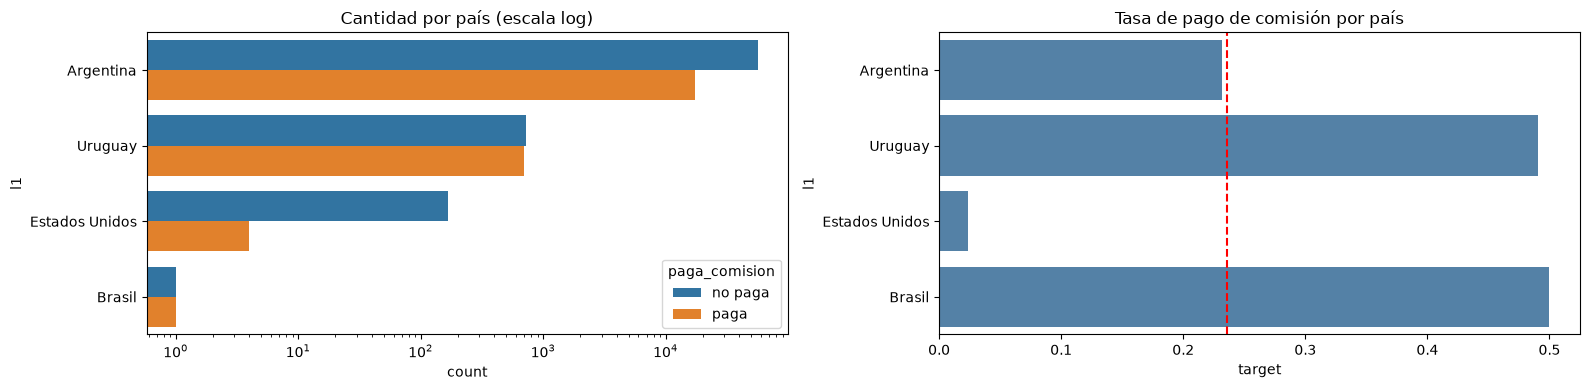

In [17]:
print(df_eda[['l1', 'l2', 'l3', 'l4', 'l5']].nunique())

fig, axes = plt.subplots(1, 2, figsize=(16,4))
sns.countplot(y='l1', data=df_eda, hue='paga_comision', ax=axes[0])
axes[0].set_xscale('log')
axes[0].set_title('Cantidad por país (escala log)')
sns.barplot(y='l1', x='target', data=df_eda, ax=axes[1], color='steelblue', errorbar=None)
axes[1].axvline(tasa_global, color='red', linestyle='--')
axes[1].set_title('Tasa de pago de comisión por país')
plt.tight_layout()
plt.show()

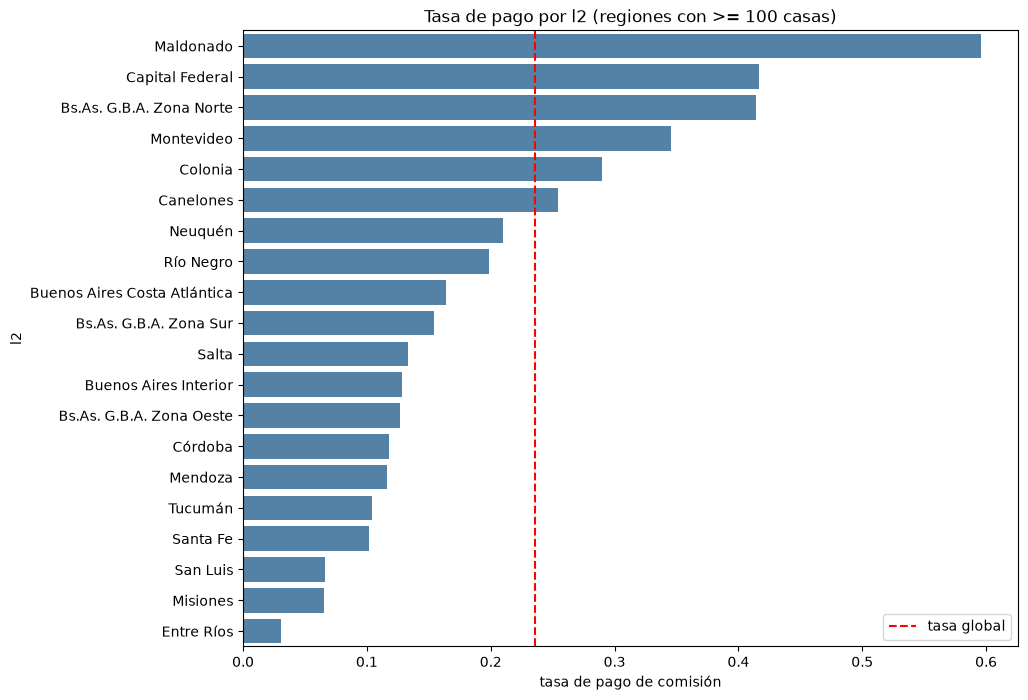

In [18]:
resumen_l2 = df_eda.groupby('l2').target.agg(cantidad='size', tasa='mean')
resumen_l2 = resumen_l2[resumen_l2.cantidad >= 100].sort_values('tasa', ascending=False)

plt.figure(figsize=(10,8))
sns.barplot(y=resumen_l2.index, x=resumen_l2.tasa, color='steelblue')
plt.axvline(tasa_global, color='red', linestyle='--', label='tasa global')
plt.xlabel('tasa de pago de comisión')
plt.title('Tasa de pago por l2 (regiones con >= 100 casas)')
plt.legend()
plt.show()

## Coordenadas (`lat`, `lon`)
El `describe()` muestra coordenadas inválidas (lat = 85, lon = -180). Filtramos a un rango razonable para graficar.

Coordenadas fuera de rango (sin contar nulos): 176


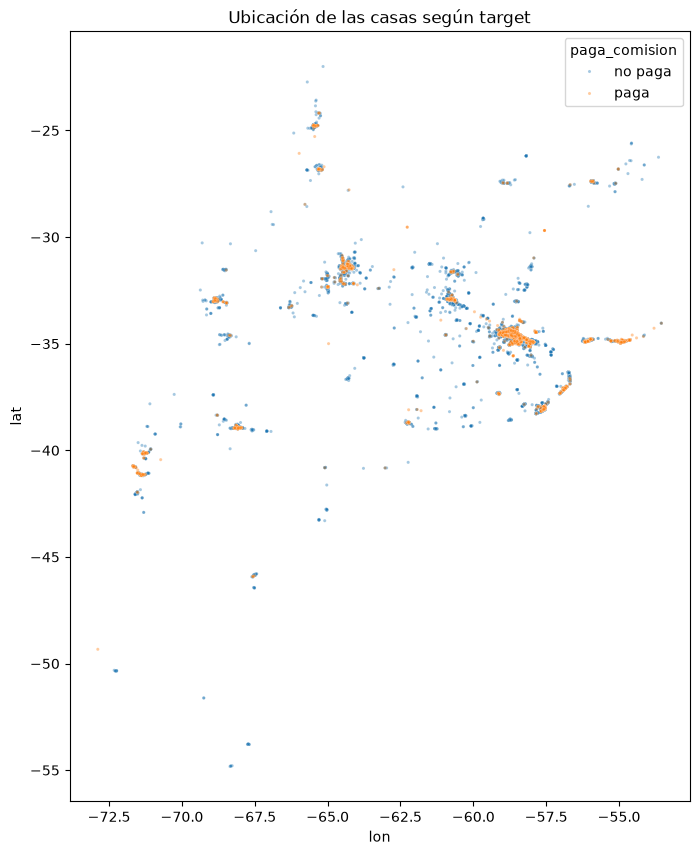

In [19]:
coord_validas = df_eda.lat.between(-56, -21) & df_eda.lon.between(-74, -52)
print("Coordenadas fuera de rango (sin contar nulos):", (~coord_validas & df_eda.lat.notna() & df_eda.lon.notna()).sum())

datos = df_eda[coord_validas].sort_values('target')  # 'paga' se dibuja arriba
plt.figure(figsize=(8,10))
sns.scatterplot(x='lon', y='lat', hue='paga_comision', data=datos, s=5, alpha=0.4)
plt.title('Ubicación de las casas según target')
plt.show()

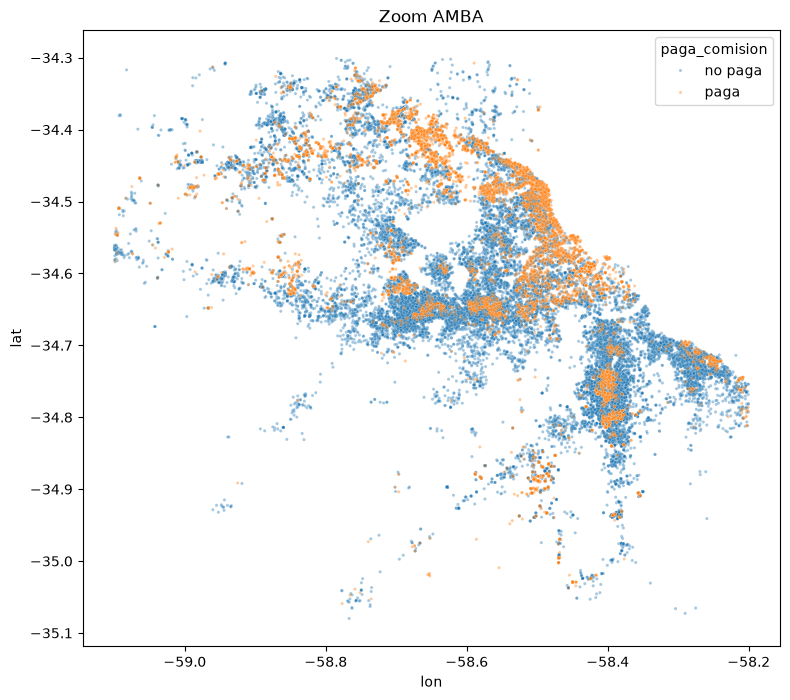

In [20]:
amba = df_eda[df_eda.lat.between(-35.1, -34.3) & df_eda.lon.between(-59.1, -58.2)].sort_values('target')
plt.figure(figsize=(9,8))
sns.scatterplot(x='lon', y='lat', hue='paga_comision', data=amba, s=5, alpha=0.4)
plt.title('Zoom AMBA')
plt.show()

## `price_period` y fechas
`price_period` solo toma `Mensual` o nulo, así que funciona como una variable binaria. De las fechas extraemos información de baja dimensionalidad: mes de publicación, duración del aviso y si sigue activo (`end_date` = 9999-12-31).

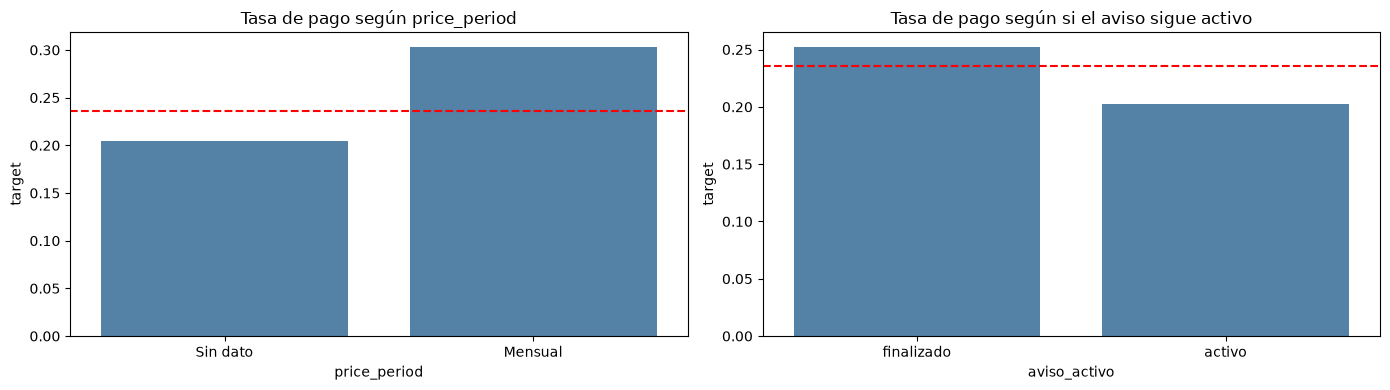

In [21]:
df_eda['price_period'] = df_eda.price_period.fillna('Sin dato')
df_eda['created_on'] = pd.to_datetime(df_eda.created_on)
df_eda['start_date'] = pd.to_datetime(df_eda.start_date)
df_eda['aviso_activo'] = (df_eda.end_date == '9999-12-31').map({True: 'activo', False: 'finalizado'})
df_eda['mes_publicacion'] = df_eda.created_on.dt.to_period('M').astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14,4))
sns.barplot(x='price_period', y='target', data=df_eda, ax=axes[0], color='steelblue', errorbar=None)
axes[0].axhline(tasa_global, color='red', linestyle='--')
axes[0].set_title('Tasa de pago según price_period')
sns.barplot(x='aviso_activo', y='target', data=df_eda, ax=axes[1], color='steelblue', errorbar=None)
axes[1].axhline(tasa_global, color='red', linestyle='--')
axes[1].set_title('Tasa de pago según si el aviso sigue activo')
plt.tight_layout()
plt.show()

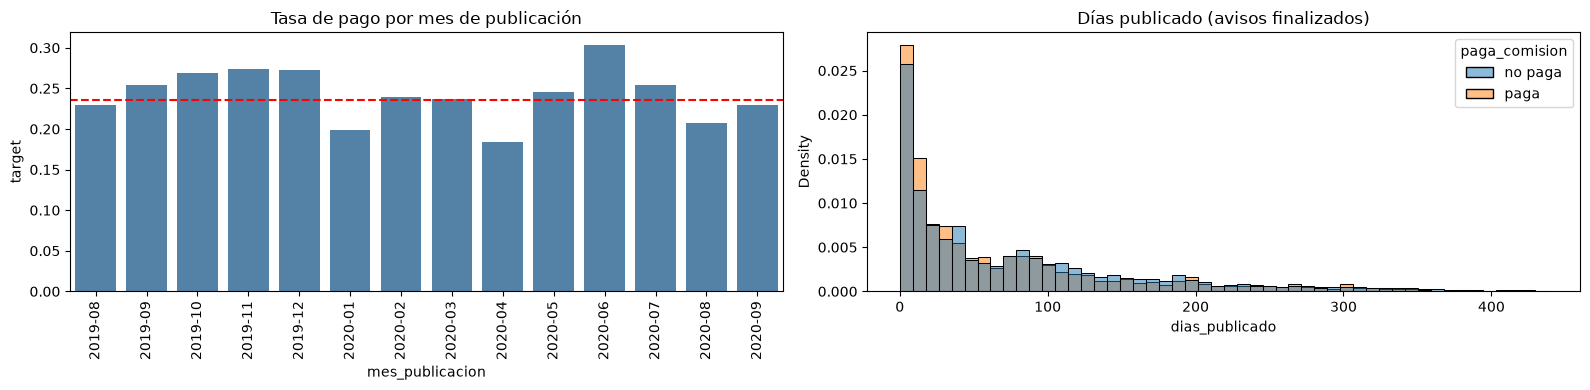

In [22]:
fin = pd.to_datetime(df_eda.end_date.where(df_eda.end_date != '9999-12-31'))
df_eda['dias_publicado'] = (fin - df_eda.start_date).dt.days

fig, axes = plt.subplots(1, 2, figsize=(16,4))
sns.barplot(x='mes_publicacion', y='target', data=df_eda.sort_values('mes_publicacion'), ax=axes[0], color='steelblue', errorbar=None)
axes[0].axhline(tasa_global, color='red', linestyle='--')
axes[0].tick_params(axis='x', rotation=90)
axes[0].set_title('Tasa de pago por mes de publicación')
sns.histplot(data=df_eda, x='dias_publicado', hue='paga_comision', bins=50, stat='density', common_norm=False, ax=axes[1])
axes[1].set_title('Días publicado (avisos finalizados)')
plt.tight_layout()
plt.show()

## Conclusiones del análisis exploratorio
Revisar contra los gráficos de arriba antes de entregar:

1. **Target desbalanceado** (~24% paga): evaluar con la función de ganancia, no con accuracy.
2. **Columnas eliminadas**: `l6` (100% nula) y `ad_type` (constante).
3. **Tamaño de la casa** (`rooms`, `bedrooms`, `bathrooms`, superficies) es lo que más separa las clases: las que pagan comisión son más grandes.
4. **Outliers / datos inválidos**: superficies negativas, `surface_covered > surface_total`, `bedrooms` extremos y coordenadas fuera de rango. Hay que tratarlos antes de modelar.
5. **Los nulos son informativos** (por ej. lat/lon y superficies faltan en distinta proporción según el target): conviene agregar indicadores de nulo además de imputar.
6. **Ubicación**: `l1`/`l2` muestran tasas muy distintas por región (Uruguay/Maldonado, CABA y Zona Norte muy por encima de la media; Estados Unidos casi nunca paga) y se pueden usar con one-hot. `l3`-`l5` necesitan target encoding o clustering.
7. **Fechas y `title`**: alta dimensionalidad; por ahora se descartan para el primer modelo, se pueden revisar features derivadas después.

Próximo paso: preprocesamiento (tratamiento de outliers, imputación, encoding) y primer modelo base.